# 29 · Project 1: TableTop, the world we use for the rest of the course

In [1]:
import mujoco, mujoco_menagerie as mm, numpy as np, matplotlib.pyplot as plt
from vlacourse import TableTop, COLORS, show_images, show_video
from vlacourse.tabletop import lookat_xyaxes, CUBE_HALF

def build_tabletop_v0(cube_colors=("red", "green", "blue"), tray_color="yellow"):
    spec = mm.get("franka_emika_panda").spec("scene")
    spec.body("hand").add_site(name="ee", pos=[0, 0, 0.1034], size=[0.005] * 3)
    spec.geom("floor").pos = [0, 0, -0.75]
    wb = spec.worldbody
    wb.add_geom(name="table", type=mujoco.mjtGeom.mjGEOM_BOX, size=[0.5, 0.65, 0.375], pos=[0.4, 0, -0.375], rgba=[0.55, 0.42, 0.3, 1])
    for c in cube_colors:
        b = wb.add_body(name=f"cube_{c}", pos=[0.5, 0, CUBE_HALF])
        b.add_freejoint(name=f"cube_{c}")
        b.add_geom(type=mujoco.mjtGeom.mjGEOM_BOX, size=[CUBE_HALF] * 3, rgba=COLORS[c], mass=0.05, friction=[1.5, 0.01, 0.001])
    tray = wb.add_body(name=f"tray_{tray_color}", pos=[0.5, 0.2, 0])
    tray.add_geom(type=mujoco.mjtGeom.mjGEOM_BOX, size=[0.06, 0.06, 0.0025], pos=[0, 0, 0.0025], rgba=COLORS[tray_color])
    for sx, sy, w, l in [(1, 0, 0.0025, 0.06), (-1, 0, 0.0025, 0.06), (0, 1, 0.06, 0.0025), (0, -1, 0.06, 0.0025)]:
        tray.add_geom(type=mujoco.mjtGeom.mjGEOM_BOX, size=[w, l, 0.01], pos=[sx * 0.0575, sy * 0.0575, 0.01], rgba=COLORS[tray_color])
    wb.add_camera(name="front", pos=[1.0, 0, 0.9], xyaxes=lookat_xyaxes([1.0, 0, 0.9], [0.42, 0, 0.0]))
    spec.body("hand").add_camera(name="wrist", pos=[0, -0.09, 0], quat=[0, 1, 0, 0], fovy=75)
    return spec

def randomize(model, data, rng, cube_colors, tray_color):
    mujoco.mj_resetDataKeyframe(model, data, 0)
    placed = []
    for name, r in [(f"tray_{tray_color}", 0.09)] + [(f"cube_{c}", 0.04) for c in cube_colors]:
        while True:
            xy = rng.uniform([0.35, -0.25], [0.65, 0.25])
            if all(np.linalg.norm(xy - p) > r + pr for p, pr in placed):
                break
        placed.append((xy, r))
        if name.startswith("tray"):
            model.body_pos[model.body(name).id][:2] = xy
        else:
            adr = model.jnt_qposadr[model.joint(name).id]
            yaw = rng.uniform(-np.pi / 4, np.pi / 4)
            data.qpos[adr:adr + 7] = [*xy, CUBE_HALF, np.cos(yaw / 2), 0, 0, np.sin(yaw / 2)]
    mujoco.mj_forward(model, data)

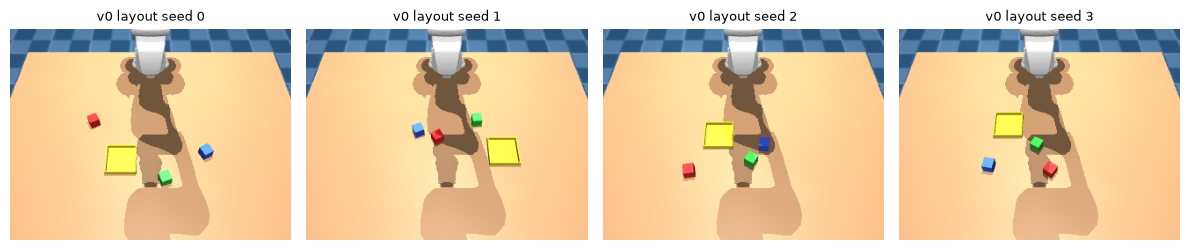

In [2]:
spec = build_tabletop_v0()
model = spec.compile(); data = mujoco.MjData(model)
rng = np.random.default_rng(0)
imgs = []
with mujoco.Renderer(model, 240, 320) as r:
    for seed in range(4):
        randomize(model, data, np.random.default_rng(seed), ("red", "green", "blue"), "yellow")
        r.update_scene(data, "front"); imgs.append(r.render())
show_images(imgs, [f"v0 layout seed {s}" for s in range(4)], cols=4)

In [3]:
env = TableTop(n_cubes=3, n_trays=1, seed=0, cameras=("front", "wrist"), image_size=(224, 224))
obs = env.reset(seed=0)
print("instruction:", obs["instruction"])
print("images:", {k: v.shape for k, v in obs["images"].items()})
print("state (ee_pos, ee_quat, gripper_width):", obs["state"].round(3))
print("qpos (7 arm joints):", obs["qpos"].round(3))
print("action: [dx, dy, dz, droll, dpitch, dyaw, grip]  |  control rate:", env.control_hz, "Hz  |  max |dpos| per step:", env.max_dpos, "m")

instruction: stack the green cube on the blue cube
images: {'front': (224, 224, 3), 'wrist': (224, 224, 3)}
state (ee_pos, ee_quat, gripper_width): [ 0.554 -0.     0.521  0.     0.707  0.707  0.     0.08 ]
qpos (7 arm joints): [ 0.     0.     0.    -1.571  0.     1.571 -0.785]
action: [dx, dy, dz, droll, dpitch, dyaw, grip]  |  control rate: 10 Hz  |  max |dpos| per step: 0.05 m


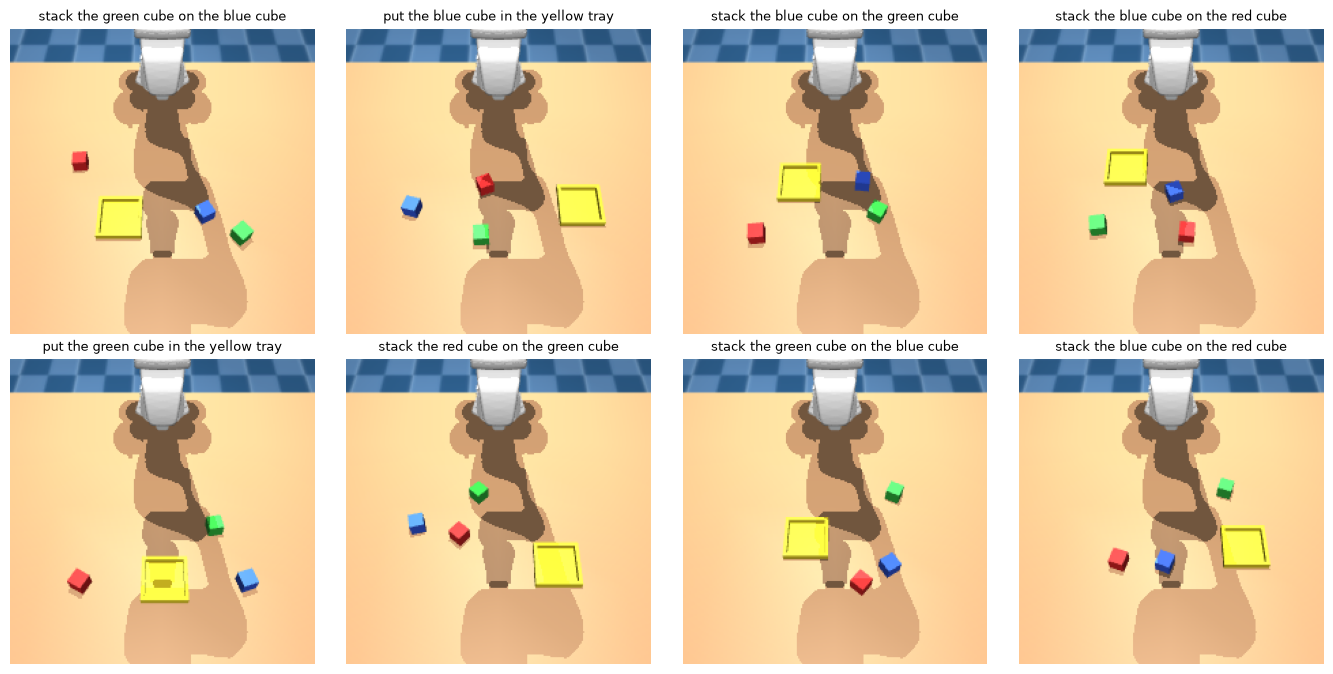

In [4]:
gallery, titles = [], []
for seed in range(8):
    o = env.reset(seed=seed)
    gallery.append(o["images"]["front"]); titles.append(o["instruction"])
show_images(gallery, titles, cols=4, size=3.4)

commanded +x 8 cm, +y 12 cm, -z 20 cm, +z 20 cm -> net displacement: [ 0.081  0.12  -0.009]


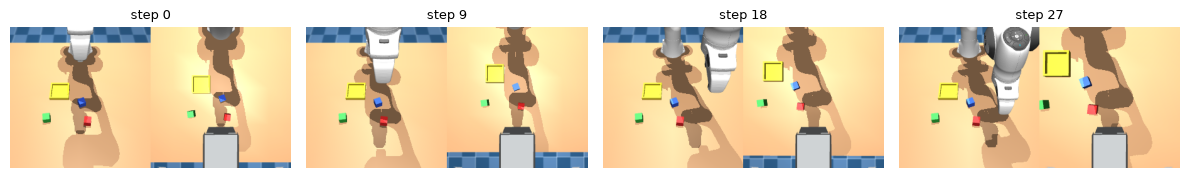

In [5]:
env.reset(seed=3)
start = env.state()[:3].copy()
frames = []
for direction, n in [((0.01, 0, 0), 8), ((0, 0.015, 0), 8), ((0, 0, -0.02), 10), ((0, 0, 0.02), 10)]:
    for _ in range(n):
        o, *_ = env.step(np.r_[direction, 0, 0, 0, 0])
        frames.append(np.hstack([o["images"]["front"], o["images"]["wrist"]]))
for _ in range(3):
    env.step(np.zeros(7))
print("commanded +x 8 cm, +y 12 cm, -z 20 cm, +z 20 cm -> net displacement:", (env.state()[:3] - start).round(3))
show_video(frames, fps=10, title="action semantics")
show_images(frames[::9], [f"step {i}" for i in range(0, len(frames), 9)], cols=len(frames[::9]))

before: False
after teleporting the cube into the tray and letting it settle: True


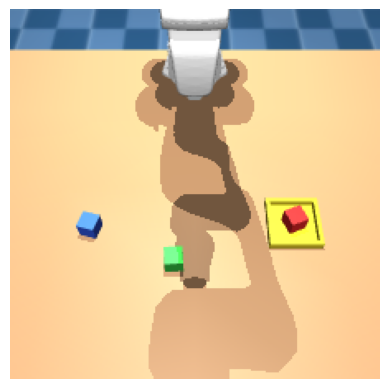

In [6]:
env.reset(seed=1, task=dict(type="place", obj="red", target="yellow", instruction="put the red cube in the yellow tray"))
print("before:", env.success())
adr = env.model.jnt_qposadr[env.model.joint("cube_red").id]
env.data.qpos[adr:adr + 3] = env.tray_pos("yellow") + [0, 0, 0.03]
for _ in range(200):
    mujoco.mj_step(env.model, env.data)
print("after teleporting the cube into the tray and letting it settle:", env.success())
plt.imshow(env.render("front")); plt.axis("off"); plt.show()

In [7]:
env.reset(seed=0)
rejected = 0
for _ in range(15):
    env.step([0.05, 0, 0, 0, 0, 0, 0])
    rejected += env.unreachable
print(f"pushing +x for 15 steps: {rejected} steps rejected as unreachable; ee stops at x = {env.state()[0]:.3f} m")

pushing +x for 15 steps: 13 steps rejected as unreachable; ee stops at x = 0.655 m


In [8]:
counts = {}
for seed in range(300):
    t = env.reset(seed=seed)["instruction"].split()[0]
    counts[t] = counts.get(t, 0) + 1
print("task mix over 300 resets:", counts)

task mix over 300 resets: {'stack': 111, 'put': 86, 'pick': 103}
